# Regresión lineal para predicción de progresión de diabetes
- age: Representa la edad del paciente, normalizada (no es la edad real, sino una representación estandarizada).
- sex: Sexo del paciente, representado como una variable numérica normalizada (valores entre -0.5 y 0.5).
- bmi: Índice de Masa Corporal (Body Mass Index, BMI), una medida del peso relativo al cuadrado de la altura.
- bp:
Promedio de presión arterial (Blood Pressure, BP), normalizada.
- s1: Nivel sérico de lípidos totales (colesterol total).
- s2: Nivel sérico de lipoproteínas de baja densidad (LDL, “colesterol malo”).
- s3: Nivel sérico de lipoproteínas de alta densidad (HDL, “colesterol bueno”).
- s4: Relación entre el colesterol total y HDL.
- s5: Nivel sérico de triglicéridos, representado como una medida numérica normalizada.
- s6: Nivel sérico de glucosa en ayuno, una medida clave en el monitoreo de la diabetes.

In [1]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

# Cargar el conjunto de datos
diabetes_data = load_diabetes()

# Convertir el conjunto de datos a un DataFrame para facilitar su manipulación
df = pd.DataFrame(data=diabetes_data.data, columns=diabetes_data.feature_names)
df['target'] = diabetes_data.target  # Agregar la variable objetivo al DataFrame

# Mostrar las primeras filas del DataFrame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## Paso 1. Exploración de datos EDA

Primero reviso cómo viene el conjunto de datos, o sea cuántas filas y columnas tiene, si hay datos vacíos o repetidos y cuáles son sus valores básicos. Las 10 variables médicas ya vienen normalizadas desde scikit-learn con media cercana a 0, mientras que target mide qué tanto avanzó la diabetes después de un año.

In [2]:
# Reviso tamaño, nulos, duplicados y tipos de datos
print("Filas y columnas:", df.shape)
print("Valores nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print()
print("Tipos de datos:")
print(df.dtypes)

# Resumen estadístico
df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(4)

Filas y columnas: (442, 11)
Valores nulos: 0
Filas duplicadas: 0

Tipos de datos:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object


,count,mean,std,min,50%,max
age,442.0,-0.0000,0.0476,-0.1072,0.0054,0.1107
sex,442.0,0.0000,0.0476,-0.0446,-0.0446,0.0507
bmi,442.0,-0.0000,0.0476,-0.0903,-0.0073,0.1706
bp,442.0,-0.0000,0.0476,-0.1124,-0.0057,0.1320
s1,442.0,-0.0000,0.0476,-0.1268,-0.0043,0.1539
s2,442.0,0.0000,0.0476,-0.1156,-0.0038,0.1988
s3,442.0,-0.0000,0.0476,-0.1023,-0.0066,0.1812
s4,442.0,-0.0000,0.0476,-0.0764,-0.0026,0.1852
s5,442.0,0.0000,0.0476,-0.1261,-0.0019,0.1336
s6,442.0,0.0000,0.0476,-0.1378,-0.0011,0.1356


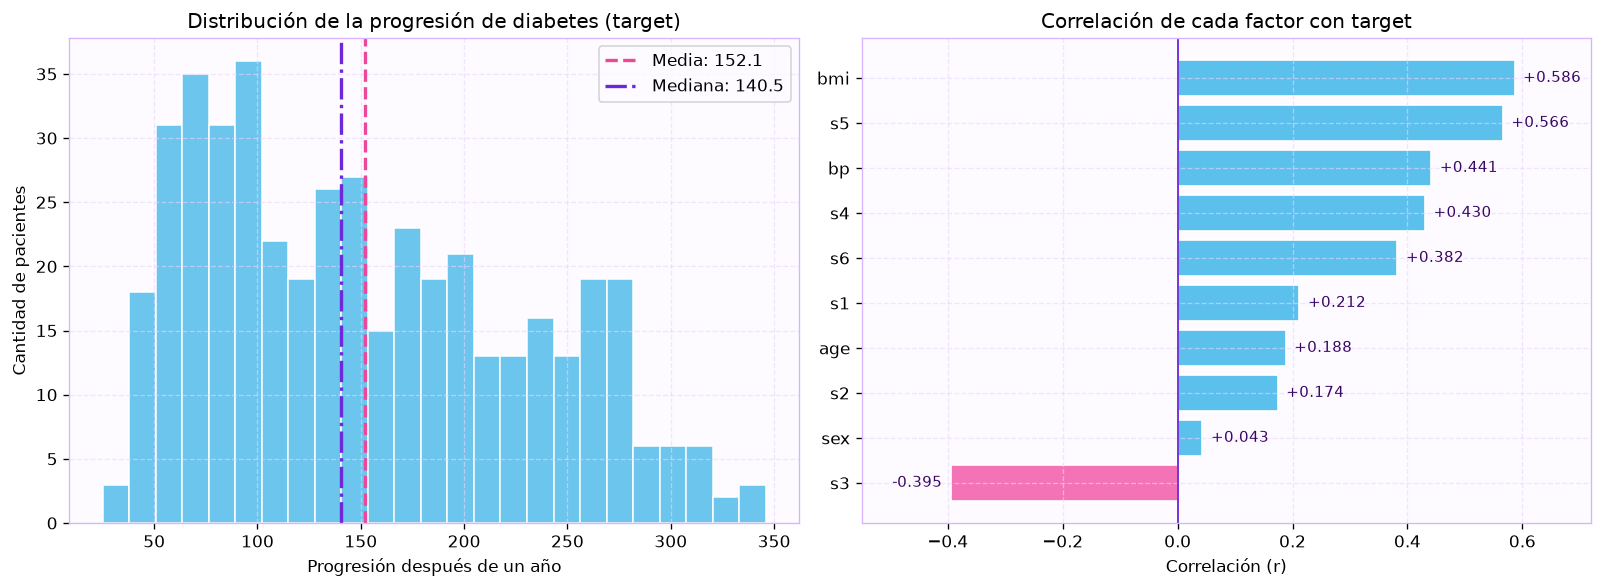

In [3]:
# Simplemente colores que me gustan para todas las gráficas
CELESTE = "#5BC0EB"
ROSA = "#EC4899"
ROSA_SUAVE = "#F472B6"
MORADO = "#8B5CF6"
MORADO_OSCURO = "#6D28D9"

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "#FDFBFF",
        "axes.edgecolor": "#D8B4FE",
        "axes.grid": True,
        "grid.color": "#E9D5FF",
        "grid.alpha": 0.6,
        "grid.linestyle": "--",
        "font.size": 10,
    }
)

# Calculo las correlaciones con la variable objetivo
corr_matrix = df.corr()
corr_target = corr_matrix["target"].drop("target").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), dpi=120)

# Distribución de la variable objetivo
axes[0].hist(df["target"], bins=25, color=CELESTE, edgecolor="white", alpha=0.9)
mean_y = df["target"].mean()
median_y = df["target"].median()
axes[0].axvline(
    mean_y, color=ROSA, linestyle="--", linewidth=2, label=f"Media: {mean_y:.1f}"
)
axes[0].axvline(
    median_y,
    color=MORADO_OSCURO,
    linestyle="-.",
    linewidth=2,
    label=f"Mediana: {median_y:.1f}",
)
axes[0].set_title("Distribución de la progresión de diabetes (target)")
axes[0].set_xlabel("Progresión después de un año")
axes[0].set_ylabel("Cantidad de pacientes")
axes[0].legend()

# Correlación de cada variable con target
colores_corr = [ROSA_SUAVE if v < 0 else CELESTE for v in corr_target.values]
bars = axes[1].barh(
    corr_target.index, corr_target.values, color=colores_corr, edgecolor="white"
)
axes[1].axvline(0, color=MORADO_OSCURO, linewidth=1.1)
axes[1].set_title("Correlación de cada factor con target")
axes[1].set_xlabel("Correlación (r)")
axes[1].set_xlim(-0.55, 0.72)

for bar, val in zip(bars, corr_target.values):
    offset = 0.015 if val >= 0 else -0.015
    ha = "left" if val >= 0 else "right"
    axes[1].text(
        val + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{val:+.3f}",
        va="center",
        ha=ha,
        fontsize=9,
        color="#3B0764",
    )

plt.tight_layout()
plt.show()

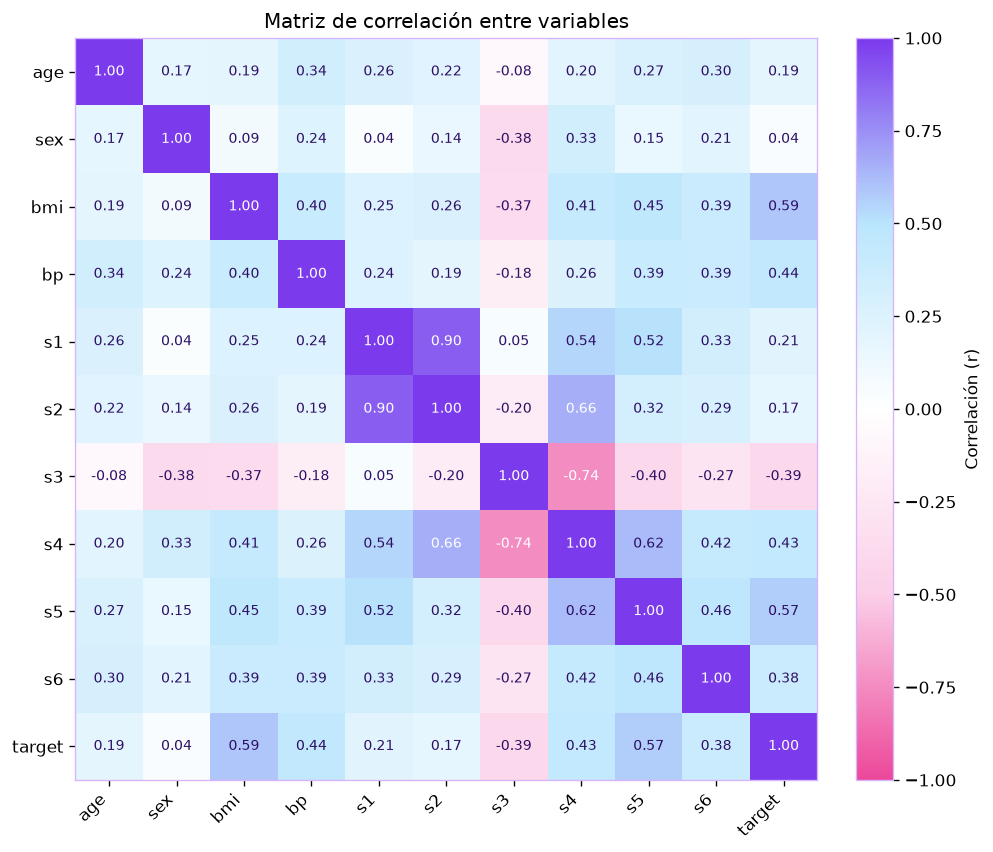

In [4]:
# Mapa de calor de correlaciones entre todas las variables
from matplotlib.colors import LinearSegmentedColormap

cmap_crm = LinearSegmentedColormap.from_list(
    "celeste_rosa_morado",
    ["#EC4899", "#FBCFE8", "#FFFFFF", "#BAE6FD", "#7C3AED"],
)

fig, ax = plt.subplots(figsize=(9, 7.2), dpi=120)
im = ax.imshow(corr_matrix.values, cmap=cmap_crm, vmin=-1, vmax=1)

labels = corr_matrix.columns.tolist()
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
ax.grid(False)

for i in range(len(labels)):
    for j in range(len(labels)):
        val = corr_matrix.values[i, j]
        txt_color = "white" if (val > 0.65 or val < -0.60) else "#2E1065"
        ax.text(
            j, i, f"{val:.2f}", ha="center", va="center", color=txt_color, fontsize=8.5
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Correlación (r)")
ax.set_title("Matriz de correlación entre variables")
plt.tight_layout()
plt.show()

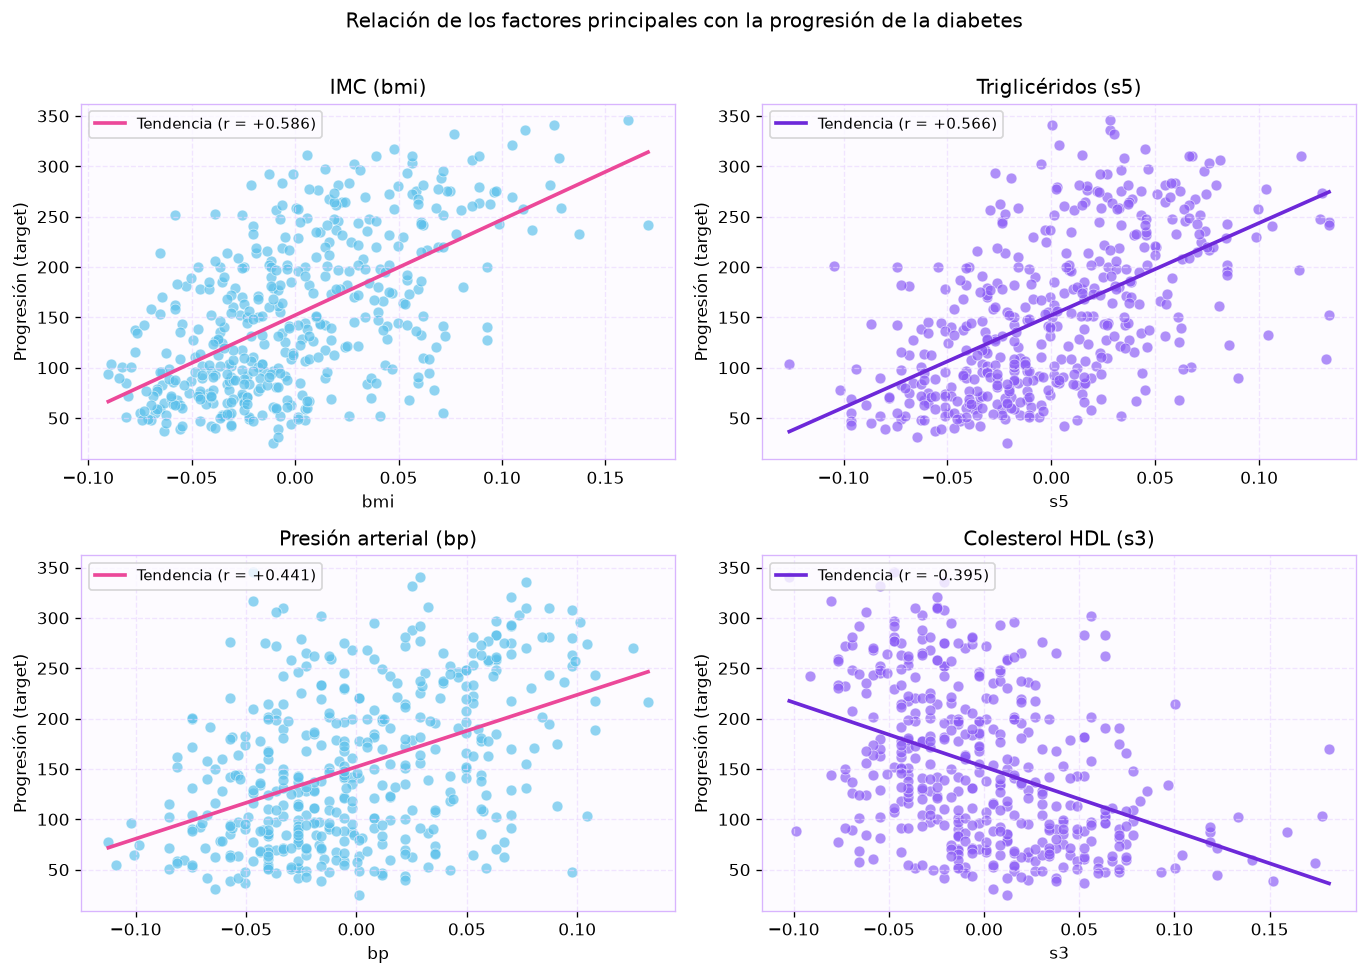

In [5]:
# Gráficas de dispersión de los 4 factores más relacionados con la progresión
top_features = [
    ("bmi", "IMC (bmi)"),
    ("s5", "Triglicéridos (s5)"),
    ("bp", "Presión arterial (bp)"),
    ("s3", "Colesterol HDL (s3)"),
]

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8), dpi=120)
axes = axes.ravel()

for idx, (ax, (col, titulo)) in enumerate(zip(axes, top_features)):
    x_vals = df[col].values
    y_vals = df["target"].values
    r_val = corr_matrix.loc[col, "target"]

    color_puntos = CELESTE if idx % 2 == 0 else MORADO
    color_linea = ROSA if idx % 2 == 0 else MORADO_OSCURO

    ax.scatter(
        x_vals,
        y_vals,
        alpha=0.68,
        color=color_puntos,
        edgecolor="white",
        linewidth=0.4,
        s=42,
    )
    m, b = np.polyfit(x_vals, y_vals, 1)
    x_line = np.linspace(x_vals.min(), x_vals.max(), 100)
    ax.plot(
        x_line,
        m * x_line + b,
        color=color_linea,
        linewidth=2.2,
        label=f"Tendencia (r = {r_val:+.3f})",
    )

    ax.set_title(titulo)
    ax.set_xlabel(col)
    ax.set_ylabel("Progresión (target)")
    ax.legend(loc="upper left", fontsize=9)

fig.suptitle(
    "Relación de los factores principales con la progresión de la diabetes", y=1.01
)
plt.tight_layout()
plt.show()

## Paso 2. Preparación y división de los datos

Ahora separo las variables médicas de entrada (X) y la progresión de la diabetes (y). Luego divido los datos en 80% para entrenar el modelo y 20% para probarlo con pacientes que el modelo no ha visto. También inclui un escalador dentro de un Pipeline para que cada variable tenga media 0 y desviación estándar 1 usando solo los datos de entrenamiento, lo que ayuda a comparar los coeficientes de forma justa.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Separo variables de entrada y variable objetivo
X = df.drop(columns="target")
y = df["target"]

# Divido en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

# Creo el flujo con escalado y regresión lineal
modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("lr", LinearRegression()),
    ]
)

Datos de entrenamiento: 353
Datos de prueba: 89


## Paso 3. Entrenamiento del modelo

Entreno el modelo de regresión lineal con el conjunto de entrenamiento y genero las predicciones tanto para entrenamiento como para prueba.

In [7]:
# Entreno el modelo
modelo.fit(X_train, y_train)

# Hago predicciones
y_train_pred = modelo.predict(X_train)
y_test_pred = modelo.predict(X_test)

# Obtengo el intercepto y los coeficientes aprendidos
regresor = modelo.named_steps["lr"]
intercepto = regresor.intercept_
coeficientes = regresor.coef_

print("Modelo entrenado.")
print(f"Intercepto: {intercepto:.2f}")

Modelo entrenado.
Intercepto: 153.74


## Paso 4. Impacto de los factores médicos

Reviso los coeficientes que aprendió el modelo para ver qué factores empujan más hacia arriba o hacia abajo la progresión de la diabetes después de un año.

In [8]:
# Armo una tabla sencilla con el nombre médico, la correlación y el coeficiente
nombres = {
    "age": "Edad",
    "sex": "Sexo",
    "bmi": "IMC",
    "bp": "Presión arterial",
    "s1": "Colesterol total",
    "s2": "Colesterol LDL",
    "s3": "Colesterol HDL",
    "s4": "Relación colesterol/HDL",
    "s5": "Triglicéridos",
    "s6": "Glucosa en ayuno",
}

tabla_coef = pd.DataFrame(
    {
        "Variable": X.columns,
        "Factor": [nombres[c] for c in X.columns],
        "Correlación": [corr_matrix.loc[c, "target"] for c in X.columns],
        "Coeficiente": coeficientes,
    }
)

tabla_coef = tabla_coef.reindex(
    tabla_coef["Coeficiente"].abs().sort_values(ascending=False).index
).reset_index(drop=True)
tabla_coef.round(3)

,Variable,Factor,Correlación,Coeficiente
0,s1,Colesterol total,0.212,-44.449
1,s5,Triglicéridos,0.566,35.161
2,bmi,IMC,0.586,25.607
3,s2,Colesterol LDL,0.174,24.641
4,bp,Presión arterial,0.441,16.829
5,s4,Relación colesterol/HDL,0.430,13.139
6,sex,Sexo,0.043,-11.512
7,s3,Colesterol HDL,-0.395,7.677
8,s6,Glucosa en ayuno,0.382,2.351
9,age,Edad,0.188,1.754


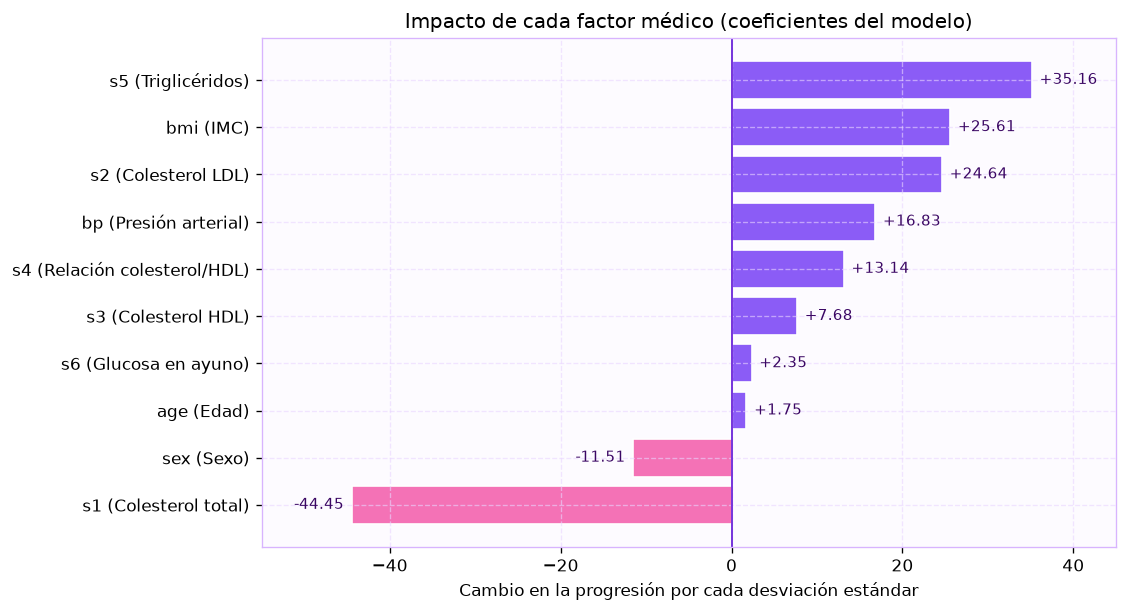

Correlación entre s1 y s2: 0.897
Correlación entre s3 y s4: -0.738


In [9]:
# Grafico los coeficientes de menor a mayor
coef_plot = tabla_coef.sort_values("Coeficiente")

fig, ax = plt.subplots(figsize=(9.5, 5.2), dpi=120)
colores_barras = [ROSA_SUAVE if v < 0 else MORADO for v in coef_plot["Coeficiente"]]
etiquetas = [f"{r['Variable']} ({r['Factor']})" for _, r in coef_plot.iterrows()]

bars = ax.barh(
    etiquetas, coef_plot["Coeficiente"], color=colores_barras, edgecolor="white"
)
ax.axvline(0, color=MORADO_OSCURO, linewidth=1.1)
ax.set_title("Impacto de cada factor médico (coeficientes del modelo)")
ax.set_xlabel("Cambio en la progresión por cada desviación estándar")
ax.set_xlim(-55, 45)

for bar, val in zip(bars, coef_plot["Coeficiente"]):
    offset = 0.9 if val >= 0 else -0.9
    ha = "left" if val >= 0 else "right"
    ax.text(
        val + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{val:+.2f}",
        va="center",
        ha=ha,
        fontsize=9,
        color="#3B0764",
    )

plt.tight_layout()
plt.show()

# Reviso qué tan relacionadas están s1 y s2
print(f"Correlación entre s1 y s2: {corr_matrix.loc['s1', 's2']:.3f}")
print(f"Correlación entre s3 y s4: {corr_matrix.loc['s3', 's4']:.3f}")

Qué dicen estos coeficientes...

Los factores que más aumentan la progresión de la diabetes en el modelo son los triglicéridos (s5), el IMC (bmi), el colesterol LDL (s2) y la presión arterial (bp).

Un detalle importante es el colesterol total (s1) porque aunque por sí solo sube junto con la diabetes, dentro del modelo aparece con coeficiente negativo (-44.45) porque s1 y s2 (LDL) están muy correlacionados entre sí (0.897), así que el modelo compensa el peso de una variable con la otra. En cambio, la edad y la glucosa en ayuno aportan un cambio bien pequeñito cuando ya se toman en cuenta el resto de los factores.

## Paso 5. Revisión de errores (residuales)

Comparo qué tanto se equivoca el modelo en cada paciente de prueba (valor real menos valor predicho) para revisar que los errores estén centrados en cero y se comporten de forma razonablemente parecida a una distribución normal.

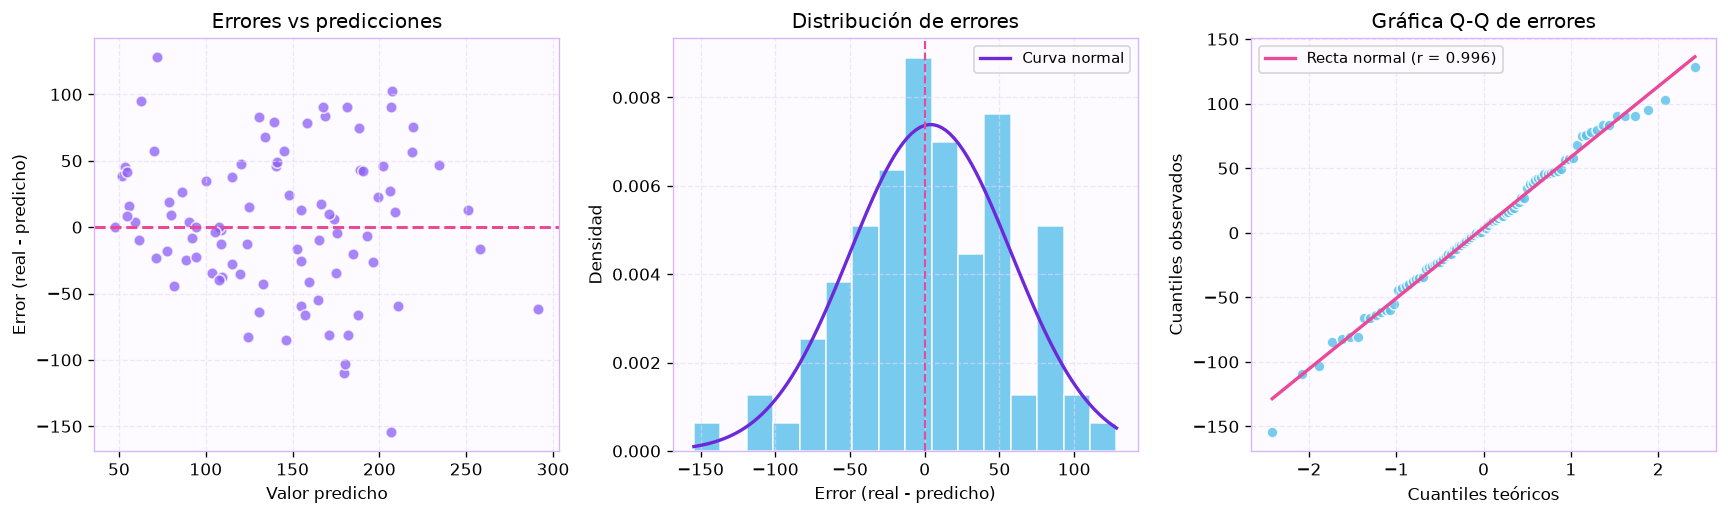

In [10]:
from scipy import stats

errores = y_test - y_test_pred

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4), dpi=120)

# Errores contra valores predichos
axes[0].scatter(y_test_pred, errores, color=MORADO, alpha=0.75, edgecolor="white", s=46)
axes[0].axhline(0, color=ROSA, linestyle="--", linewidth=1.8)
axes[0].set_title("Errores vs predicciones")
axes[0].set_xlabel("Valor predicho")
axes[0].set_ylabel("Error (real - predicho)")

# Histograma de errores
axes[1].hist(
    errores, bins=16, density=True, color=CELESTE, alpha=0.82, edgecolor="white"
)
x_norm = np.linspace(errores.min(), errores.max(), 100)
axes[1].plot(
    x_norm,
    stats.norm.pdf(x_norm, errores.mean(), errores.std()),
    color=MORADO_OSCURO,
    linewidth=2,
    label="Curva normal",
)
axes[1].axvline(0, color=ROSA, linestyle="--", linewidth=1.3)
axes[1].set_title("Distribución de errores")
axes[1].set_xlabel("Error (real - predicho)")
axes[1].set_ylabel("Densidad")
axes[1].legend(fontsize=9)

# Gráfica Q-Q para ver normalidad
(osm, osr), (slope, intercept, r_qq) = stats.probplot(errores, dist="norm")
axes[2].scatter(osm, osr, color=CELESTE, alpha=0.82, edgecolor="white", s=42)
axes[2].plot(
    osm,
    slope * osm + intercept,
    color=ROSA,
    linewidth=2,
    label=f"Recta normal (r = {r_qq:.3f})",
)
axes[2].set_title("Gráfica Q-Q de errores")
axes[2].set_xlabel("Cuantiles teóricos")
axes[2].set_ylabel("Cuantiles observados")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

## Paso 6. Evaluación final del modelo

Mido el desempeño final usando MAE, MSE, RMSE y R2 en los datos de entrenamiento, en los datos de prueba y con validación cruzada de 5 bloques para confirmar que los resultados sean estables.

Resultados finales del modelo de regresión lineal

Entrenamiento -> MAE: 43.48 | MSE: 2868.55 | RMSE: 53.56 | R2: 0.5279
Prueba        -> MAE: 42.79 | MSE: 2900.19 | RMSE: 53.85 | R2: 0.4526
CV 5-Fold     -> MAE: 44.28 (+/- 2.10) | RMSE: 54.69 (+/- 1.37) | R2: 0.4823 (+/- 0.0493)


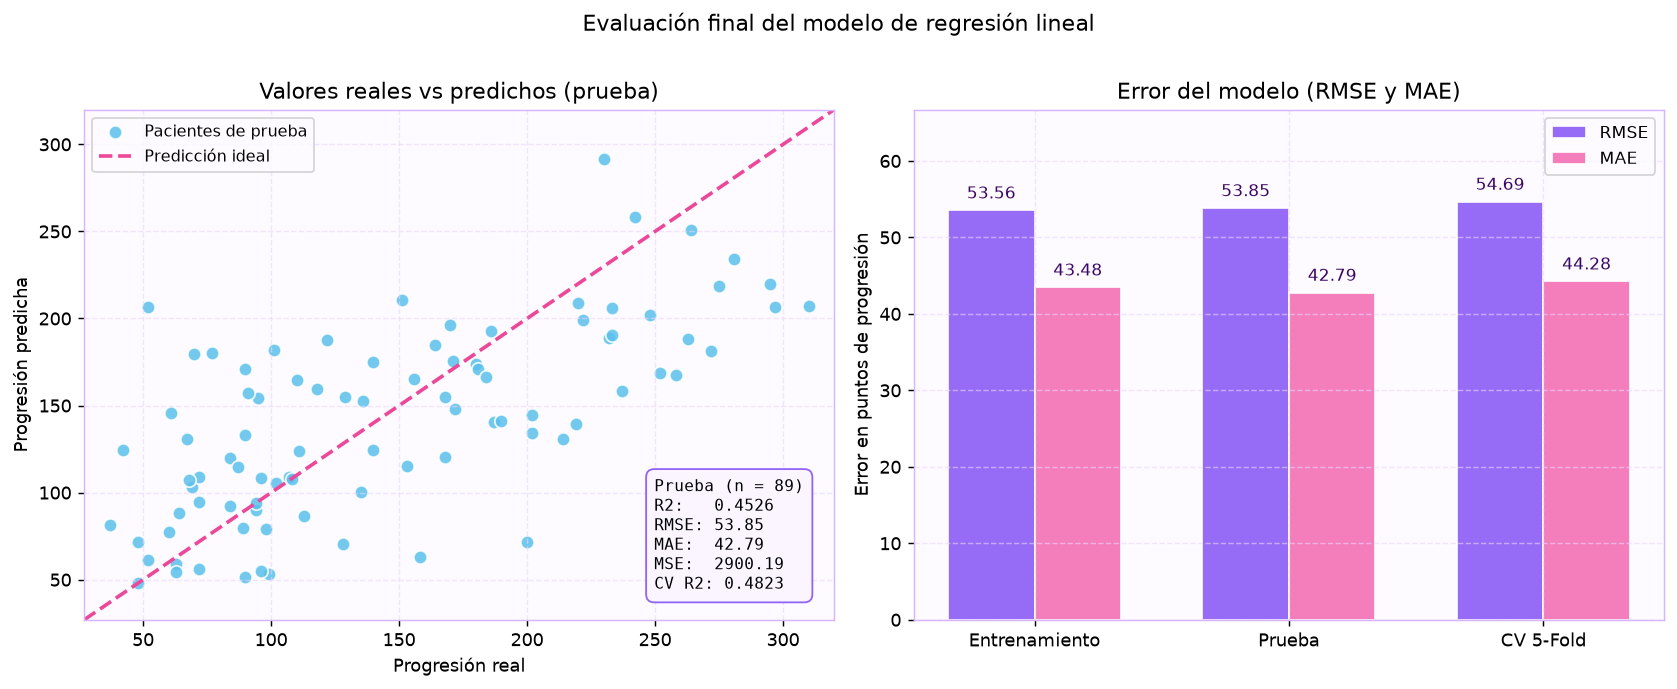

In [11]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
)
from sklearn.model_selection import cross_validate

# Métricas en entrenamiento
mae_train = mean_absolute_error(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
rmse_train = root_mean_squared_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

# Métricas en prueba
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = root_mean_squared_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

# Validación cruzada de 5 bloques
cv = cross_validate(
    modelo,
    X,
    y,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2",
    },
)

cv_mae = -cv["test_mae"]
cv_mse = -cv["test_mse"]
cv_rmse = -cv["test_rmse"]
cv_r2 = cv["test_r2"]

# Imprimo el resumen directo en consola
print("Resultados finales del modelo de regresión lineal")
print()
print(
    f"Entrenamiento -> MAE: {mae_train:.2f} | MSE: {mse_train:.2f} | RMSE: {rmse_train:.2f} | R2: {r2_train:.4f}"
)
print(
    f"Prueba        -> MAE: {mae_test:.2f} | MSE: {mse_test:.2f} | RMSE: {rmse_test:.2f} | R2: {r2_test:.4f}"
)
print(
    f"CV 5-Fold     -> MAE: {cv_mae.mean():.2f} (+/- {cv_mae.std():.2f}) | RMSE: {cv_rmse.mean():.2f} (+/- {cv_rmse.std():.2f}) | R2: {cv_r2.mean():.4f} (+/- {cv_r2.std():.4f})"
)

# Gráfica final de evaluación
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), dpi=130)

# Valores reales vs predichos
axes[0].scatter(
    y_test,
    y_test_pred,
    color=CELESTE,
    alpha=0.85,
    edgecolor="white",
    s=55,
    label="Pacientes de prueba",
)
lims = [
    min(y_test.min(), y_test_pred.min()) - 10,
    max(y_test.max(), y_test_pred.max()) + 10,
]
axes[0].plot(
    lims, lims, color=ROSA, linestyle="--", linewidth=2, label="Predicción ideal"
)
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_title("Valores reales vs predichos (prueba)")
axes[0].set_xlabel("Progresión real")
axes[0].set_ylabel("Progresión predicha")
axes[0].legend(loc="upper left", fontsize=9)

texto = (
    f"Prueba (n = {len(y_test)})\n"
    f"R2:   {r2_test:.4f}\n"
    f"RMSE: {rmse_test:.2f}\n"
    f"MAE:  {mae_test:.2f}\n"
    f"MSE:  {mse_test:.2f}\n"
    f"CV R2: {cv_r2.mean():.4f}"
)
axes[0].text(
    0.96,
    0.05,
    texto,
    transform=axes[0].transAxes,
    fontsize=9,
    family="monospace",
    verticalalignment="bottom",
    horizontalalignment="right",
    multialignment="left",
    bbox=dict(
        boxstyle="round,pad=0.5", facecolor="#FAF5FF", edgecolor=MORADO, alpha=0.95
    ),
)

# Comparación de RMSE y MAE
grupos = ["Entrenamiento", "Prueba", "CV 5-Fold"]
x_pos = np.arange(len(grupos))
ancho = 0.34

rmse_vals = [rmse_train, rmse_test, cv_rmse.mean()]
mae_vals = [mae_train, mae_test, cv_mae.mean()]

b1 = axes[1].bar(
    x_pos - ancho / 2,
    rmse_vals,
    ancho,
    label="RMSE",
    color=MORADO,
    alpha=0.9,
    edgecolor="white",
)
b2 = axes[1].bar(
    x_pos + ancho / 2,
    mae_vals,
    ancho,
    label="MAE",
    color=ROSA_SUAVE,
    alpha=0.92,
    edgecolor="white",
)

axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(grupos)
axes[1].set_ylabel("Error en puntos de progresión")
axes[1].set_ylim(0, max(rmse_vals) * 1.22)
axes[1].set_title("Error del modelo (RMSE y MAE)")
axes[1].legend(fontsize=9.5)

for grupo_barras in (b1, b2):
    for bar in grupo_barras:
        h = bar.get_height()
        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            h + 1.0,
            f"{h:.2f}",
            ha="center",
            va="bottom",
            fontsize=9.5,
            color="#3B0764",
        )

fig.suptitle("Evaluación final del modelo de regresión lineal", y=1.01)
plt.tight_layout()
plt.show()

Conclusion...

El modelo de regresión lineal logra un R2 de 0.4526 y un RMSE de 53.85 en el conjunto de prueba. Como estos valores son muy parecidos a los de entrenamiento (RMSE de 53.56) y a los de validación cruzada (RMSE promedio de 54.69 y R2 de 0.4823), pues se puede ver que el modelo generaliza bien y no se sobreajusta.

A nivel médico, los triglicéridos (s5), el índice de masa corporal (bmi), la presión arterial (bp) y el colesterol LDL (s2) son los factores que más se asocian con un mayor avance de la diabetes después de un año, mientras que un mayor colesterol HDL (s3) tiende a relacionarse con una menor progresión.

Al final los errores se reparten cerca de cero y siguen bien una forma normal.